# 基于langchain搭建一个完整的RAG系统
+ 文档加载器：从许多不同的来源加载文档
+ 文档转换器：分割文档，删除多余的文档等
+ 文本词嵌入模型：采取非结构化文本，并把它变成一个浮点数的列表 矢量存储：存储和搜索嵌入式数据
+ 向量存储：存储和搜索embedding数据
+ 检索器：查询你的数据<br>
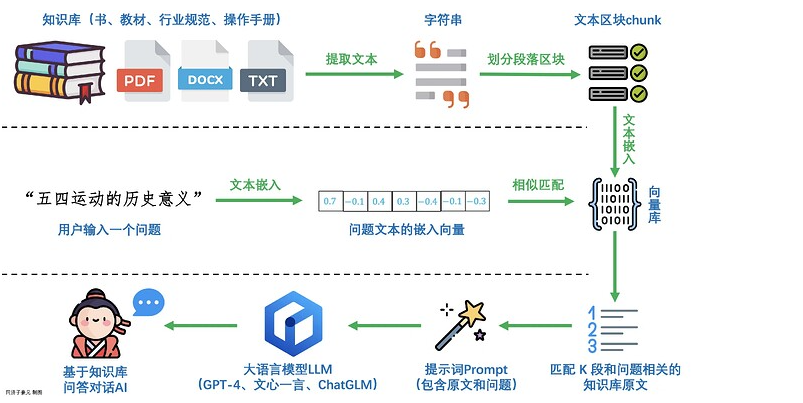<br>

**数据集**<br>
https://tianchi.aliyun.com/competition/entrance/532154<br>
https://competition.coggle.club/<br>

## 数据连接处理流程
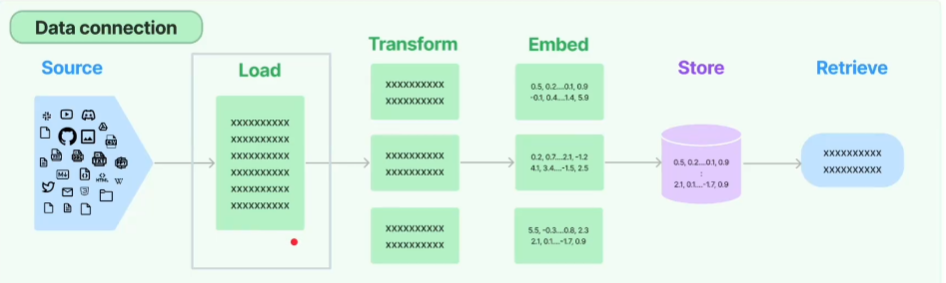<br>
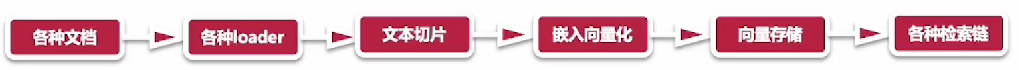<br>
### 文档加载器
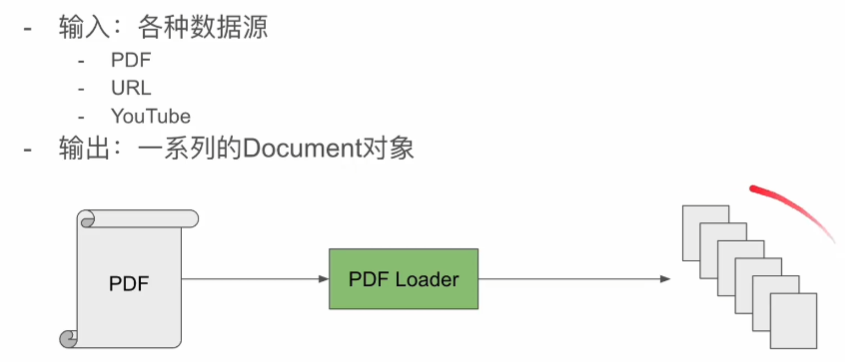 <br/>
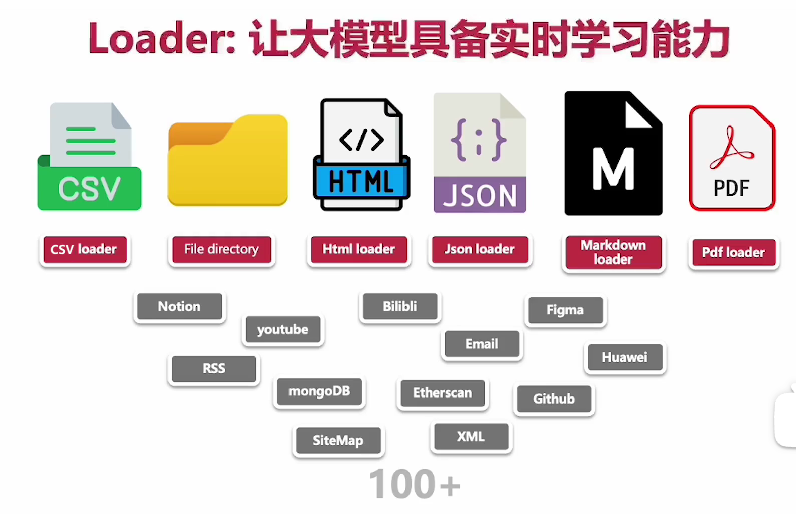 <br/>
langchain 提供了大约100多种文档加载器

我们可以使用 LangChain 的 PyMuPDFLoader 来读取知识库的 PDF 文件。PyMuPDFLoader 是 PDF 解析器中速度最快的一种，结果会包含 PDF 及其页面的详细元数据，并且每页返回一个文档。<br>

In [ ]:
# pip install pymupdf==1.25.5 -i https://pypi.tuna.tsinghua.edu.cn/simple
from langchain_community.document_loaders import PyMuPDFLoader
# 创建一个 PyMuPDFLoader Class 实例，输入为待加载的 pdf 文档路径
pdf_loader = PyMuPDFLoader("/teacher_data/xiaowei/bigmodel/RAG/car_info.pdf")
# 调用 PyMuPDFLoader Class 的函数 load 对 pdf 文件进行加载
pdf_pages = pdf_loader.load()

文档加载后储存在 pages 变量中:<br>
page 的变量类型为 List<br>
打印 pages 的长度可以看到 pdf 一共包含多少页<br>

In [ ]:
print(f"载入后的变量类型为：{type(pdf_pages)}，",  
      f"该 PDF 一共包含 {len(pdf_pages)} 页")

载入后的变量类型为：<class 'list'>， 该 PDF 一共包含 354 页


page 中的每一元素为一个文档，变量类型为 langchain_core.documents.base.Document, 文档变量类型包含两个属性<br>
page_content 包含该文档的内容。<br>
meta_data 为文档相关的描述性数据。<br>

In [7]:
pdf_page = pdf_pages[0]
print(f"每一个元素的类型：{type(pdf_page)}.", 
    f"该文档的描述性数据：{pdf_page.metadata}")

每一个元素的类型：<class 'langchain_core.documents.base.Document'>. 该文档的描述性数据：{'producer': 'PDFlib+PDI 9.0.6 (C++/Win64)', 'creator': 'PTC Arbortext Publishing Engine', 'creationdate': '2023-06-16T15:35:59+08:00', 'source': './data/car_info.pdf', 'file_path': './data/car_info.pdf', 'total_pages': 354, 'format': 'PDF 1.7', 'title': '', 'author': '', 'subject': '', 'keywords': '', 'moddate': '2023-06-16T17:41:45+08:00', 'trapped': '', 'modDate': "D:20230616174145+08'00'", 'creationDate': "D:20230616153559+08'00'", 'page': 0}


In [8]:
print(f"查看该文档的内容:\n{pdf_page.page_content}")

查看该文档的内容:
欢迎
感谢您选择了具有优良安全性、舒适性、动力性和经济性的Lynk & Co领克汽车。
首次使用前请仔细、完整地阅读本手册内容，将有助于您更好地了解和使用车辆。
本手册中的所有资料均为出版时的最新资料，但本公司将对产品进行不断的改进和优化，您所购的车辆可能与本手册中的描述有所不同，请以实际
接收的车辆为准。
如您有任何问题，或需要预约服务，请拨打电话4006-010101 联系我们。您也可以开车前往Lynk & Co领克中心。
在抵达之前，请您注意驾车安全。
© 领克汽车销售有限公司


In [ ]:


#from langchain_community.document_loaders import Docx2txtLoader
#适用于 .docx 格式（Word 2007及以后版本）

# pip install python-docx==1.1.2 -i https://pypi.tuna.tsinghua.edu.cn/simple
# 是专门读写 .docx 格式文件的 Python 库，是Docx2txtLoader 的底层依赖


from langchain_community.document_loaders import UnstructuredWordDocumentLoader

# pip install unstructured==0.17.2 -i https://pypi.tuna.tsinghua.edu.cn/simple
#可以保留文档结构（标题、段落等）

# #加载文档
# 底层用 unstructured 库
# 能保留文档结构（标题层级、段落分隔等）
# 适合需要结构化信息的 RAG 场景

filepath="./data/峨眉山讲解词.docx"
doc_loader = UnstructuredWordDocumentLoader(file_path=filepath,mode="elements")
doc = doc_loader.load()

print(type(doc[0]))
print(len(doc))
print(doc[0].page_content)
print(doc[0].metadata)

In [ ]:
'''
模式	粒度	适用场景
single	整个文档	文档较短，需整体处理
elements	段落/标题/列表等元素	需要精细结构化解析，保留语义边界
paged	按页	需要按页面区分内容

使用 elements 模式时，每个 Document 的 metadata 会包含额外信息：
{
    "source": "xxx.docx",
    "category": "Title",        # 元素类型
    "element_id": "abc123",     # 元素唯一ID
    "filename": "xxx.docx",
    "page_number": 1,
    ...
}

category 常见值包括：Title、NarrativeText、ListItem、Table、Header、Footer 等。
需要对category进行过滤
'''

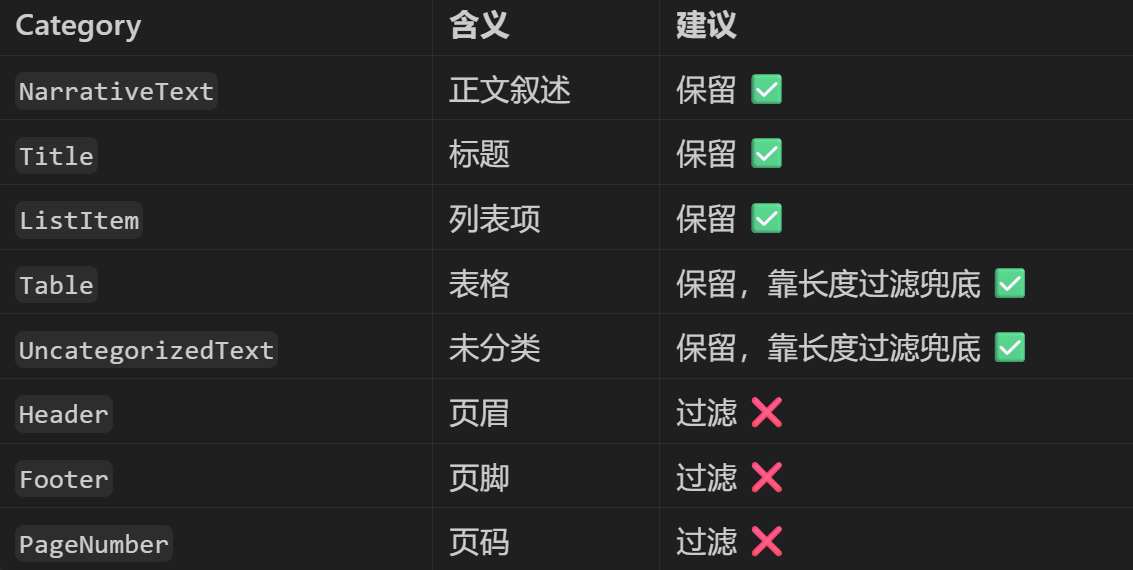

In [ ]:
#新版本langchian有个一单独的包在做结构化输入与加载
from langchain_unstructured import UnstructuredLoader
loader = UnstructuredLoader("./峨眉山讲解词.docx",mode="elements") #mode = single/elements/paged

docs = loader.load() #将整个文档加载进来全部返回 
# docs = loader.lazy_load() #按元素加载，返回一个生成器

# for doc in docs:
#     print(doc)


# 只过滤这些明确无用的类型
SKIP_CATEGORIES = {"Header", "Footer", "PageNumber"}
# UncategorizedText 保留，不加入 SKIP_CATEGORIES
filtered = [
    doc for doc in docs
    if doc.metadata.get("category") not in SKIP_CATEGORIES
]


### 数据清洗
我们期望知识库的数据尽量是有序的、优质的、精简的，因此我们要删除低质量的、甚至影响理解的文本数据。我们可以使用正则匹配来去掉HTML、URL、邮箱、电话、异常字符等，同时还需要处理记载进来的文档中的一些大的异常的换行符号<br>

In [ ]:
#基于正则化
from langchain_community.document_loaders import PyMuPDFLoader
import re

# 1. 加载文档
loader = PyMuPDFLoader(r"./car_info.pdf")
documents = loader.load()

# 2. 清洗文本（在分割前）
def clean_pdf_text(text: str) -> str:
    _SECTION_HEADERS = "提示信息|警告！|注意！|说明！|帮助信息|图标和插图说明"
    """清洗 PDF 提取文本中的排版折行，保留段落/标题结构。"""
    text = text.replace("\r\n", "\n").replace("\r", "\n")

    # 合并汉字之间的排版折行（如 造\n成、版\n本）
    text = re.sub(r"(?<=[\u4e00-\u9fff])\n(?=[\u4e00-\u9fff])", "", text)

    # 合并标点后的折行（如 部位，\n其他）
    text = re.sub(r"(?<=[，。；：！？、）」』])\n(?=[\u4e00-\u9fff])", "", text)

    # 在常见标题词后恢复换行，避免「提示信息警告！」粘在一起
    text = re.sub(rf"({_SECTION_HEADERS})(?=[\u4e00-\u9fff])", r"\1\n", text)

    # 多个空行压成段落分隔
    text = re.sub(r"\n{3,}", "\n\n", text)

    return text.strip()

# 对每个文档应用清洗
from langchain_core.documents import Document

cleaned_documents = []
for doc in documents:
    cleaned_content = clean_pdf_text(doc.page_content)
    cleaned_doc = Document(
        page_content=cleaned_content,
        metadata=doc.metadata
    )
    cleaned_documents.append(cleaned_doc)
print(cleaned_documents[0])

#### 基于jionlp库清洗

In [ ]:
#基于jionlp库清洗

from langchain_core.documents import Document
from langchain_community.document_loaders import PyMuPDFLoader
import jionlp as jio

#例1
text = "请拨打电话13800138000，或400-123-4567"

jio.clean_text(text)           # 一键清洗：HTML、URL、邮箱、电话、异常字符
jio.remove_phone_number(text)  # 只删电话
jio.remove_email(text)         # 只删邮箱
jio.remove_url(text)           # 只删 URL
jio.split_sentence(text)       # 中文分句（做 chunk 很有用）

print(jio.clean_text(text))


#例2

from langchain_community.document_loaders import PyMuPDFLoader
import jionlp as jio

# 1. 加载
docs = PyMuPDFLoader("car_info.pdf").load()
print(docs[10])

print("--------------------------------")

# 2. 文档级清洗（切块前）
for doc in docs:
    doc.page_content = jio.clean_text(doc.page_content)


#### 基于clean-text

In [ ]:
# 安装: pip install clean-text
from cleantext import clean
from langchain_core.documents import Document

loader = PyMuPDFLoader("document.pdf")
documents = loader.load()


def advanced_clean(text: str) -> str:
    """使用 clean-text 库进行高级清洗"""
    cleaned = clean(
        text,
        fix_unicode=True,           # 修复 Unicode
        to_ascii=False,             # 不转为 ASCII（保留中文）
        lower=False,                # 不转小写
        no_line_breaks=False,       # 保留换行
        no_urls=True,               # 移除 URL
        no_emails=True,             # 移除邮箱
        no_phone_numbers=True,      # 移除电话
        no_numbers=False,           # 保留数字
        no_digits=False,            # 保留数字
        no_currency_symbols=False,  # 保留货币符号
        no_punct=False,             # 保留标点
        replace_with_url="",
        replace_with_email="",
        replace_with_phone_number=""
    )
    return cleaned

# 应用到文档
def clean_documents_advanced(documents):
    cleaned = []
    for doc in documents:
        cleaned_content = advanced_clean(doc.page_content)
        if len(cleaned_content) > 20:
            cleaned.append(Document(
                page_content=cleaned_content,
                metadata=doc.metadata
            ))
    return cleaned

print(cleaned_documents[0])

## 文本分割器
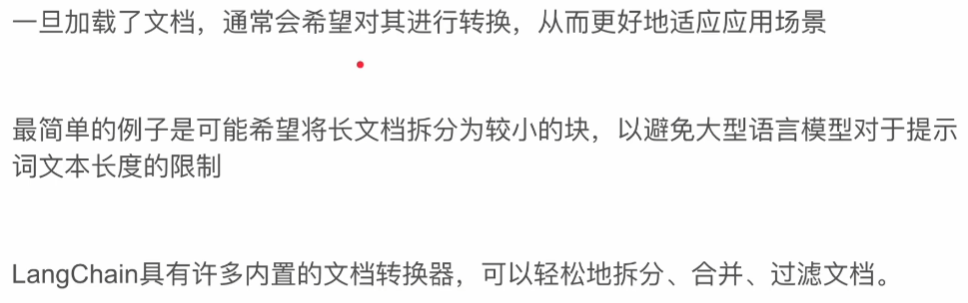 <br>

由于单个文档的长度往往会超过模型支持的上下文，导致检索得到的知识太长超出模型的处理能力，因此，在构建向量知识库的过程中，我们往往需要对文档进行分割，将单个文档按长度或者按固定的规则分割成若干个 chunk，然后将每个 chunk 转化为词向量，存储到向量数据库中。<br>

在检索时，我们会以 chunk 作为检索的元单位，也就是每一次检索到 k 个 chunk 作为模型可以参考来回答用户问题的知识，这个 k 是我们可以自由设定的。<br>

Langchain 中文本分割器都根据 chunk_size (块大小)和 chunk_overlap (块与块之间的重叠大小)进行分割。<br>
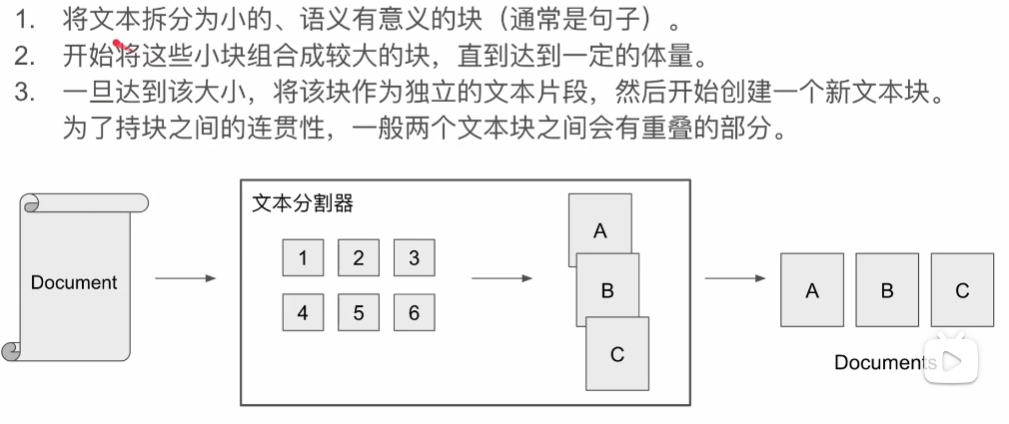 

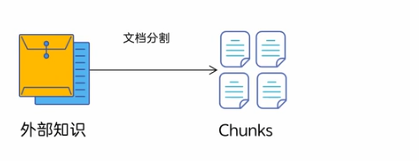

缺陷:
+ 1.分割粒度太大可能导致检索不精准，粒度太小可能导致信息不全面
+ 2.问题的答案可能跨越两个片段

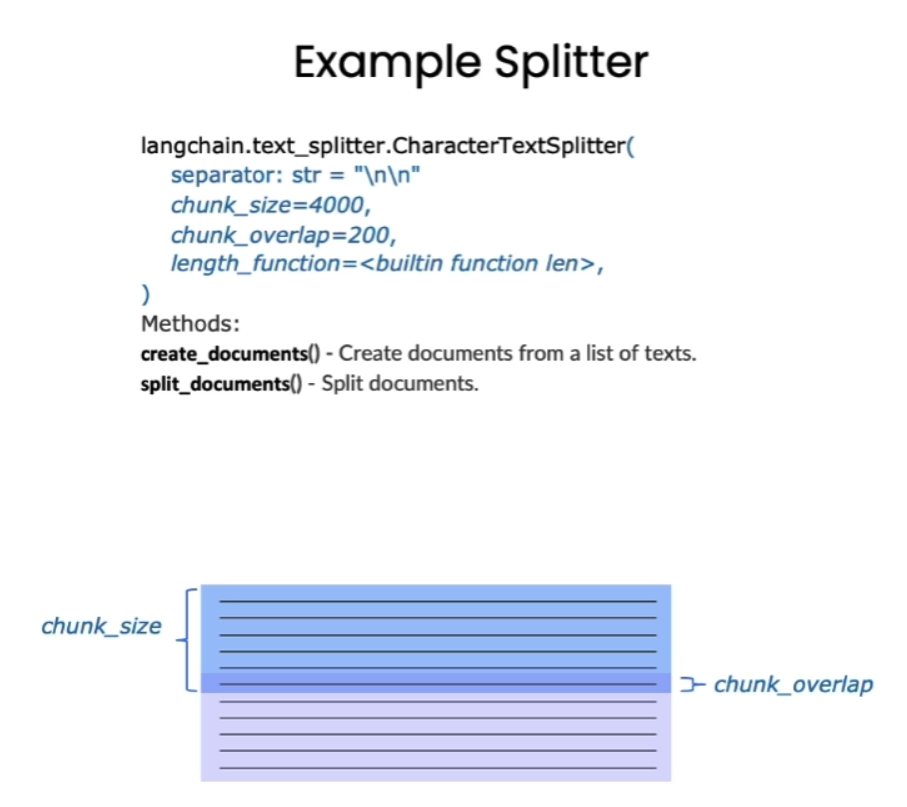<br>
+ chunk_size 指每个块包含的字符或 Token （如单词、句子等）的数量<br>

+ chunk_overlap 指两个块之间共享的字符数量，用于保持上下文的连贯性，避免分割丢失上下文信息<br>

Langchain 提供多种文档分割方式，区别在怎么确定块与块之间的边界、块由哪些字符/token组成、以及如何测量块大小

+ RecursiveCharacterTextSplitter(): 按字符串分割文本，递归地尝试按不同的分隔符进行分割文本。
+ CharacterTextSplitter(): 按字符来分割文本。
+ MarkdownHeaderTextSplitter(): 基于指定的标题来分割markdown 文件。
+ TokenTextSplitter(): 按token来分割文本。
+ SentenceTransformersTokenTextSplitter(): 按token来分割文本
+ Language(): 用于 CPP、Python、Ruby、Markdown 等。
+ NLTKTextSplitter(): 使用 NLTK（自然语言工具包）按句子分割文本。
+ SpacyTextSplitter(): 使用 Spacy按句子的切割文本。

In [ ]:
''' 
RecursiveCharacterTextSplitter 递归字符文本分割

将按不同的字符递归地分割(按照这个优先级["\n\n", "\n", " ", ""])，
这样就能尽量把所有和语义相关的内容尽可能长时间地保留在同一位置
RecursiveCharacterTextSplitter需要关注的是4个参数：

* separators - 分隔符字符串数组
* chunk_size - 每个文档的字符数量限制
* chunk_overlap - 两份文档重叠区域的长度
* length_function - 长度计算函数
'''
from langchain_text_splitters import RecursiveCharacterTextSplitter
# 定义文本切割器,按句子进行分割
text_splitter = RecursiveCharacterTextSplitter(
    # 设置分隔符，这里使用 ".!?" 来匹配句子结束符号
    separators=["\n\n", "\n", "(?<=\。！？ )", " ", ""],
    # 设置每个片段的最大长度 chunk_size 一般根据文档内容或大小来设置,
    chunk_size=50,
    # 设置每个片段之间的重叠字符数量   chunk_overlap = chunk_size * 20% 或 30%
    chunk_overlap=10,
    # 设置是否长内容优先
    length_function=len
)

# 对文本进行分割
text =""" 
LangChain: 一个让你的LLM变得更强大的开源框架。
LangChain 就是一个 LLM 编程框架，你想开发一个基于 LLM 应用，需要什么组件它都有，
直接使用就行；甚至针对常规的应用流程，它利用链(LangChain中Chain的由来)这个概念已经内置标准化方案了。
下面我们从新兴的大语言模型（LLM）技术栈的角度来看看为何它的理念这么受欢迎。
"""
texts = text_splitter.split_text(text)
print(texts)

# split_docs = text_splitter.split_documents(pdf_pages)
# print(f"切分后的文件数量：{len(split_docs)}")
# print(f"切分后的字符数（可以用来大致评估 token 数）：{sum([len(doc.page_content) for doc in split_docs])}")

https://mp.weixin.qq.com/s/ZQt0z44sZPeoPLf5d6KaDg

https://mp.weixin.qq.com/s/aic-9ZKq_0lt7YHsClC93g

In [ ]:
from langchain_text_splitters import (
    RecursiveCharacterTextSplitter,
    CharacterTextSplitter,
    TokenTextSplitter,
    MarkdownHeaderTextSplitter
)
from langchain_community.document_loaders import PyMuPDFLoader

# 加载文档
loader = PyMuPDFLoader(r"C:/Users/guaizi/Desktop/教学文档/大模型教学文档/large_model/bigmodel/data/car_info.pdf")
docs = loader.load()

# 方法1: 递归字符分割器（推荐） 递归分块
recursive_splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=70,
    separators=["\n\n", "\n", "(?<=\。！？ )", " ", ""],
    length_function=len,
    is_separator_regex=True    # 分隔符是否为正则
)

'''
RecursiveCharacterTextSplitter 参数说明：

1. separators：分隔符列表，按优先级从高到低依次尝试切割。常见取值：
   - "\n\n"：按段落（双换行）切
   - "\n"：按行切
   - "(?<=\。！？ )"：按中文句末标点切（需配合 is_separator_regex=True）
   - " "：按空格切
   - ""：按字符切（兜底）

2. chunk_size：每个文本块的最大长度。一般根据文档内容和模型上下文窗口设置，如 50、500、1000。

3. chunk_overlap：相邻文本块之间的重叠长度，用于避免语义在切割处断裂。通常取 chunk_size 的 20%~30%。

4. length_function：计算文本长度的函数。默认是 len（按字符数）；也可换成按 token 计数的函数。

5. is_separator_regex：内容是否按正则表达式解析。默认 False；使用正则分隔符时需设为 True。

6. keep_separator：是否在切分后的文本块中保留分隔符。默认 False。

7. add_start_index：是否在每个块的 metadata 中记录该块在原文中的起始字符位置。默认 False。
'''



# 方法2: 基于 Token 的递归分割器 先按语义分隔符递归切，再用 token 计数约束，通常可读性更好
token_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    encoding_name="cl100k_base",
    chunk_size=200,  # token 数量
    chunk_overlap=50
)

# 方法3: Token 分割器  ，按 token数量直接切
pure_token_splitter = TokenTextSplitter(
    encoding_name="cl100k_base",
    chunk_size=200,
    chunk_overlap=50
)

# 选择一个分割器进行文档分割
split_docs = recursive_splitter.split_documents(docs)
print(f"文档被分割为 {len(split_docs)} 个块")

# 查看分割结果
for i, doc in enumerate(split_docs[:3]):  # 查看前3个块
    print(f"块 {i+1}: {doc.page_content[:100]}...")


# 定义要分割的标题层级
headers_to_split_on = [
    ("#", "Header 1"),      # 一级标题
    ("##", "Header 2"),     # 二级标题
    ("###", "Header 3"),    # 三级标题
]

# 创建分割器
markdown_splitter = MarkdownHeaderTextSplitter(
    headers_to_split_on=headers_to_split_on
)

# Markdown 文档示例
markdown_document = """
# 领克汽车用户手册

领克汽车是一个高端品牌。

## 车辆规格

### 车顶行李架

车顶行李架最大载荷：75kg
建议使用原厂配件。

### 发动机参数

发动机类型：2.0T涡轮增压
最大功率：254马力

## 保养信息

### 保修期限

整车质保：3年或10万公里
动力系统：5年或15万公里

### 保养周期

首保：5000公里
常规保养：每10000公里
"""

# 执行分割
md_header_splits = markdown_splitter.split_text(markdown_document)

# 查看结果
for i, split in enumerate(md_header_splits):
    print(f"=== 块 {i+1} ===")
    print(f"内容: {split.page_content}")
    print(f"元数据: {split.metadata}")
    print()

### 过滤分块

In [ ]:
# 切块（中文可用递归分块 + 按句边界）
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyMuPDFLoader

# 加载文档
loader = PyMuPDFLoader(r"C:/Users/guaizi/Desktop/教学文档/大模型教学文档/large_model/bigmodel/data/car_info.pdf")
docs = loader.load()

splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=50,
    separators=["\n\n", "\n", "。", "！", "？", " "],
    length_function=len
)
chunks = splitter.split_documents(docs)

# 块级过滤 过滤掉过短的块
chunks = [c for c in chunks if len(c.page_content.strip()) > 30]

## 文本词嵌入(Word Embedding)
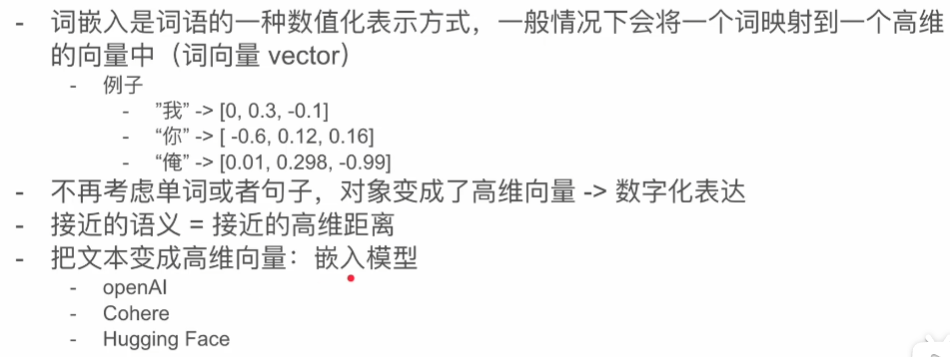

In [ ]:


#https://mp.weixin.qq.com/s/-JyQFteRHHabVpxQLDjBHQ 向量模型怎么选？
# from langchain.embeddings import DashScopeEmbeddings
# api_key="sk-eb70e9512e3046c38961ddbc5ea65b27"
# embedding_model = DashScopeEmbeddings(
#     model="text-embedding-v3",
#     dashscope_api_key=api_key)

from langchain_ollama import OllamaEmbeddings
embedding_model = OllamaEmbeddings(model="qwen3-embedding:0.6b")

# #测试词嵌入模型
text = "这是一个测试文本。"
embedding = embedding_model.embed_query(text)
print(f"Embedding: {embedding}")


embeddings = embedding_model.embed_documents([
    "hello world",
    "你好，世界",
    "LangChain: 一个让你的LLM变得更强大的开源框架。",
    "LangChain 就是一个 LLM 编程框架，你想开发一个基于 LLM 应用，需要什么组件它都有，直接使用就行；甚至针对常规的应用流程，它利用链(LangChain中Chain的由来)这个概念已经内置标准化方案了。下面我们从新兴的大语言模型（LLM）技术栈的角度来看看为何它的理念这么受欢迎。",
])
print(f"embeddings: {embeddings}")
print(f"embedding的长度: {len(embeddings)}")

## 向量数据库
向量数据库是专门用来存储和查询向量的数据库，其存储的向量来自于对文本、语音、图像、视频等的向量化。与传统数据库相比，向量数据库可以处理更多非结构化数据（比如图像和音频）。在机器学习和深度学习中，数据通常以向量形式表示。<br>
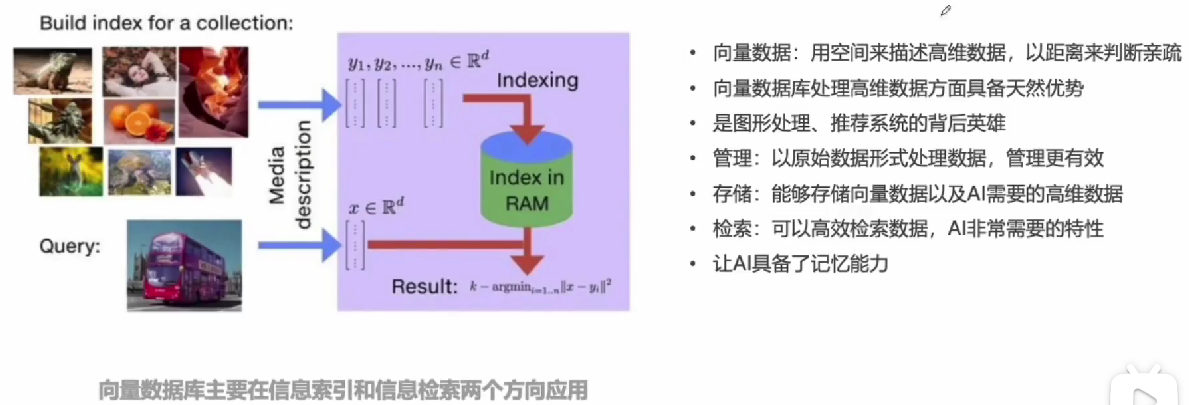<br>
***向量数据库，是专门为向量检索设计的中间件***<br>

In [ ]:
"""
向量数据库存储格式
"""

{
  "id": "doc_001",
  "vector": [0.123, -0.456, 0.789, ...],
  "metadata": {
    "text": "原始文档内容",
    "source": "file.txt",
    "timestamp": "2025-11-26"
  }
}

In [ ]:
# pip install Chroma -i https://pypi.tuna.tsinghua.edu.cn/simple
# pip install chromadb -i https://pypi.tuna.tsinghua.edu.cn/simple

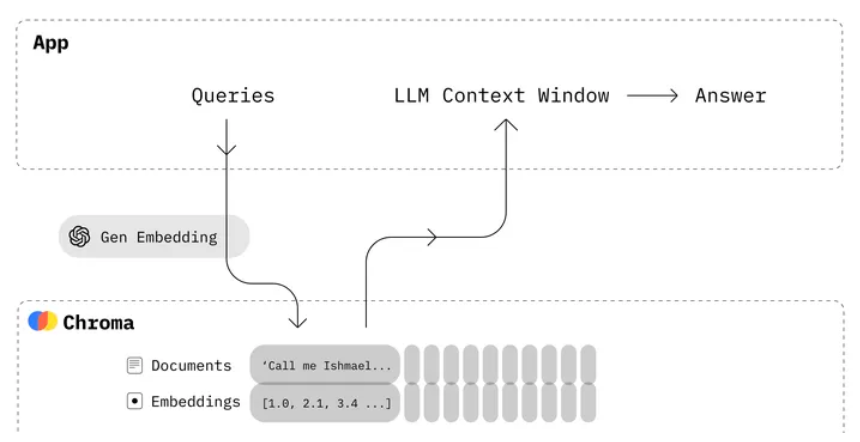<br>
ChromaDB（也称为Chroma）是一个开源的向量数据库，主要用于AI和机器学习场景。它的主要功能是存储和查询向量数据，这些数据通常是通过嵌入（embedding）算法从文本、图像等数据转换而来的。ChromaDB的设计目标是简化大模型应用的构建过程，允许开发者轻松地将知识、事实和技能等文档整合进大型语言模型（LLM）中。

ChromaDB的特点包括：

+ 轻量级: 它是一个基于向量检索库实现的轻量级向量数据库。
+ 易用性: 提供简单的API，易于集成和使用。
+ 功能丰富: 支持存储嵌入及其元数据、嵌入文档和查询、搜索嵌入等功能。
+ 集成: 可以直接插入LangChain、LlamaIndex、OpenAI等。
+ 多语言支持: 包括Python和JavaScript客户端SDK。
+ 开源: 采用Apache 2.0开源许可。

启动chrome服务<br>
chroma run

In [ ]:
import chromadb
 
# collection名称
collection_name="test_01"
 
def init_db_client():
    """初始化数据库客户端"""
    #chroma_client = chromadb.PersistentClient(path="./testdb") #本地
    chroma_client = chromadb.HttpClient(host='localhost', port=8000) #远端
    return chroma_client
 
def create_collection(collection_name):
    """创建collection
       Collection 是向量数据库中的一个容器或表，用于存储相关的向量数据及其元数据。可以类比为：
       关系型数据库中的表（Table）"""
    chroma_client = init_db_client()
    collection=chroma_client.get_or_create_collection(name=collection_name)
    return collection
 
def add_documents(collection, documents):
    """写入数据"""
    collection.add(
        documents=documents,  # 文档的原文
        ids=[f"id{i}" for i in range(len(documents))]  # 每个文档的 id
    )
 
def db_test():
    collection = create_collection(collection_name)
    datas=[
        "小明喜欢吃苹果", 
        "小红喜欢吃榴莲",
        "小明的女朋友是小丽",
        "王老师是一个好老师",
        "小李喜欢吃香蕉",
        "小王的男朋友是大帅哥"
    ]
 
    add_documents(collection, datas)
 
    # 查询数据
    res=collection.query(
        query_texts=["谁是老师"],
        n_results=5
    )
 
    print(res)
 
db_test()

In [ ]:
'''
使用langchain_community.vectorstores  储存text
'''
from langchain_community.vectorstores import Chroma
from langchain_ollama import OllamaEmbeddings
embedding_model = OllamaEmbeddings(model="qwen3-embedding:0.6b")

datas=[
        "小明喜欢吃苹果", 
        "小红喜欢吃榴莲",
        "小明的女朋友是小丽",
        "王老师是一个好老师",
        "小李喜欢吃香蕉",
        "小王的男朋友是大帅哥"
    ]
#保存数据
db = Chroma.from_texts(
    texts=datas,
    embedding=embedding_model,
    collection_name="text_data",   # 集合名称
    persist_directory="./test_data/chroma_db"  # 数据库存储路径

)

query="谁是老师"
results = db.similarity_search_with_score(query,k=1)
print(results)

In [ ]:
'''
使用langchain_community.vectorstores  储存documents
'''
from langchain_community.vectorstores import Chroma
from langchain_ollama import OllamaEmbeddings
from langchain_core.documents import Document
from langchain_community.document_loaders import PyMuPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

embedding_model = OllamaEmbeddings(model="qwen3-embedding:0.6b")

loader = PyMuPDFLoader(file_path="/teacher_data/wtb/教学文档/大模型教学文档/large_model/bigmodel/data/car_info.pdf")
docs = loader.load()

# 定义文本切割器,按句子进行分割
text_splitter = RecursiveCharacterTextSplitter(
    # 设置分隔符，这里使用 ".!?" 来匹配句子结束符号
    separators=["\n\n", "\n", "(?<=\。！？ )", " ", ""],
    # 设置每个片段的最大长度 chunk_size 一般根据文档内容或大小来设置,
    chunk_size=50,
    # 设置每个片段之间的重叠字符数量   chunk_overlap = chunk_size * 20% 或 30%
    chunk_overlap=10,
    # 设置是否长内容优先
    length_function=len
)
chunks = text_splitter.split_documents(docs)
db = Chroma.from_documents(
    documents=chunks,
    collection_name="car_info", #集合名称
    embedding=embedding_model,
    persist_directory="./test_data/chroma_db",# 储存的位置
)

query = "谁是老师"
results = db.similarity_search_with_score(query, k=1)
print(results)
print(results[0][0].page_content, results[0][0].metadata, results[0][1])

In [ ]:
"""
追加文档
"""

from langchain_community.vectorstores import Chroma
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_ollama import OllamaEmbeddings
# 1) embedding（要和原库一致）
embedding_model = OllamaEmbeddings(model="qwen3-embedding:0.6b")
# 2) 重新加载已有向量库
db = Chroma(
    persist_directory="./test_data/chroma_db",
    collection_name="car_info",   # 你之前的 collection 名
    embedding_function=embedding_model
)
# 3) 加载 PDF
loader = PyPDFLoader("./data/机器学习讲义.pdf")
pdf_docs = loader.load()  # 每页一个 Document
# 4) 切分（强烈建议，不要整页直接入库）
text_splitter = RecursiveCharacterTextSplitter(
    # 设置分隔符，这里使用 ".!?" 来匹配句子结束符号
    separators=["\n\n", "\n", "(?<=\。！？ )", " ", ""],
    # 设置每个片段的最大长度 chunk_size 一般根据文档内容或大小来设置,
    chunk_size=50,
    # 设置每个片段之间的重叠字符数量   chunk_overlap = chunk_size * 20% 或 30%
    chunk_overlap=10,
    # 设置是否长内容优先
    length_function=len
)
chunks = text_splitter.split_documents(pdf_docs)
# 5) 追加到已有库
db.add_documents(chunks)
# 6) 验证
res = db.similarity_search("这份PDF讲了什么", k=3)
for d in res:
    print(d.metadata, d.page_content[:80])

## 检索器

### 向量间相似度计算<br>
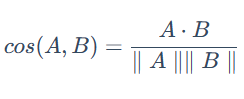<br>

In [ ]:
import numpy as np
from numpy import dot
from numpy.linalg import norm

def cos_sim(a, b):
    '''余弦距离 -- 越大越相似'''
    return dot(a, b)/(norm(a)*norm(b))

def get_embeddings(texts):
    list=[]
    for t in texts:
        embedding = embedding_model.embed_query(t)
        list.append(embedding)
    return list

In [ ]:
query = "国际争端"

# 且能支持跨语言
# query = "global conflicts"

documents = [
    "联合国就苏丹达尔富尔地区大规模暴力事件发出警告",
    "土耳其、芬兰、瑞典与北约代表将继续就瑞典“入约”问题进行谈判",
    "日本岐阜市陆上自卫队射击场内发生枪击事件 3人受伤",
    "国家游泳中心（水立方）：恢复游泳、嬉水乐园等水上项目运营",
    "我国首次在空间站开展舱外辐射生物学暴露实验",
]

query_vec = get_embeddings([query])[0]
doc_vecs = get_embeddings(documents)

for vec in doc_vecs:
    print(cos_sim(query_vec, vec))


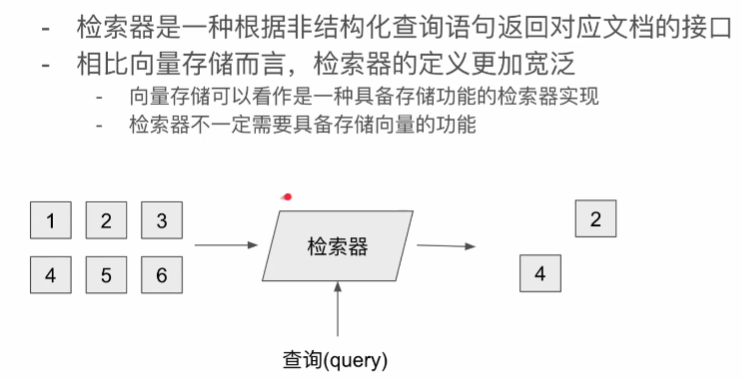<br>

In [ ]:
'''
检索器 
'''
from langchain_openai import OpenAIEmbeddings
from langchain_community.vectorstores import Chroma
persist_dir = "./chroma_db"   # 你之前保存时的目录
collection_name = "my_docs"   # 你之前用的集合名（如果当时指定了）
embedding_model = OllamaEmbeddings(model="qwen3-embedding:0.6b")
# 关键：只要目录里已有数据，这里就是“加载”，不会重新建库
vectordb = Chroma(
    persist_directory="./test_data/chroma_db",
    collection_name="car_info",
    embedding_function=embedding_model
)
retriever = vectordb.as_retriever(search_kwargs={"k": 3})
docs = retriever.invoke("你的查询问题")
print(docs[0].page_content)

## 检索器转换为检索工具

In [ ]:
from langgraph.checkpoint.memory import MemorySaver
from langchain_core.tools.retriever import create_retriever_tool   #将检索器转换为工具
from langchain_milvus import Milvus
from langchain_ollama import OllamaEmbeddings,ChatOllama
from langchain.agents import create_agent

llm = ChatOllama(model="qwen3:8b",url="http://localhost:11434")

embeddings = OllamaEmbeddings(model="nomic-embed-text:latest")
vector = Milvus(
    embedding_function=embeddings,
    connection_args={
        "uri": "http://192.168.1.105:19530"},
    collection_name="car_info_collection")
# 将向量存储转换为检索器
retriever = vector.as_retriever(search_kwargs={"k": 2})
retriever_tool = create_retriever_tool(
    retriever,
    name="info_retriever",#工具的名称
    description="搜索并返回领克汽车相关信息。",#工具的描述，agent会根据这个描述决定何时使用该工具
)
print(retriever_tool.invoke("领克汽车车顶行李架最大载荷是多少?"))


## RAG常见的问题

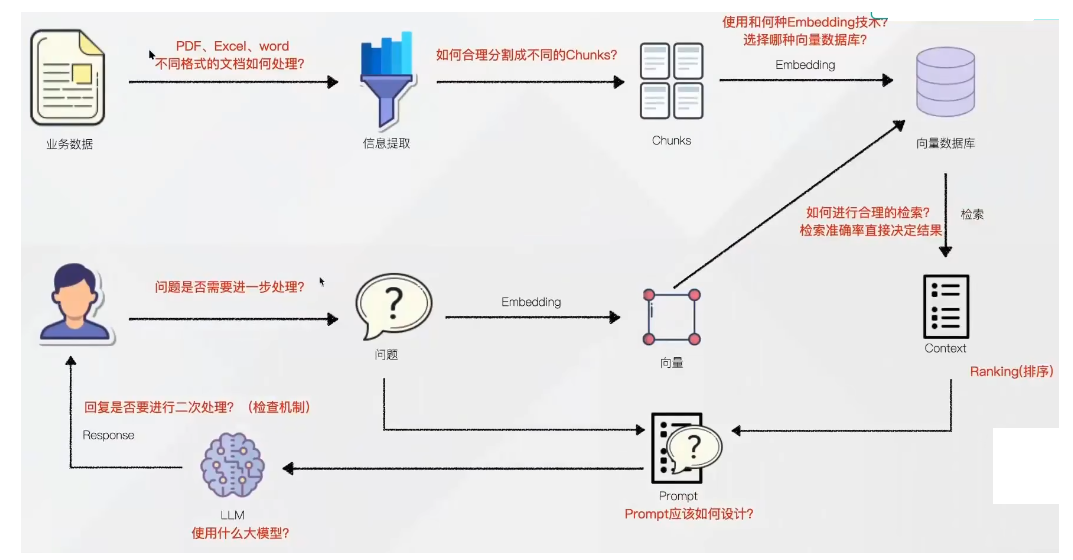

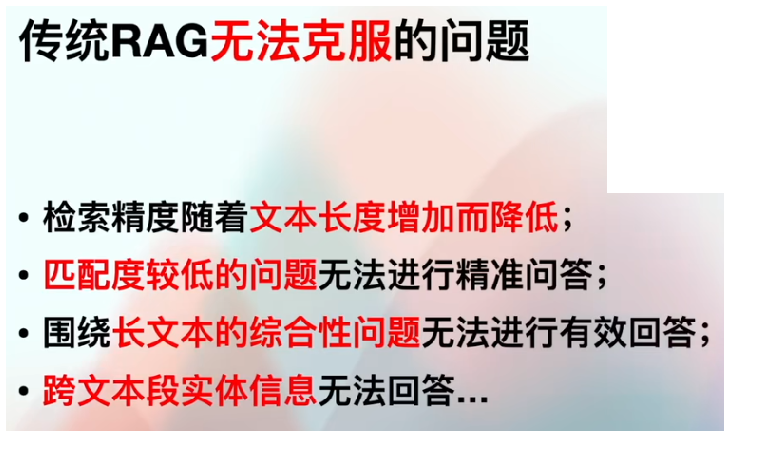

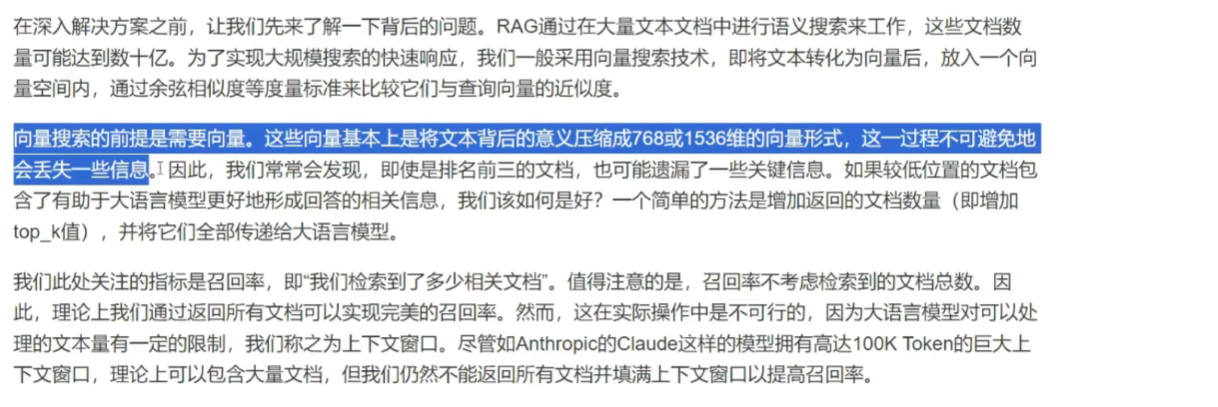

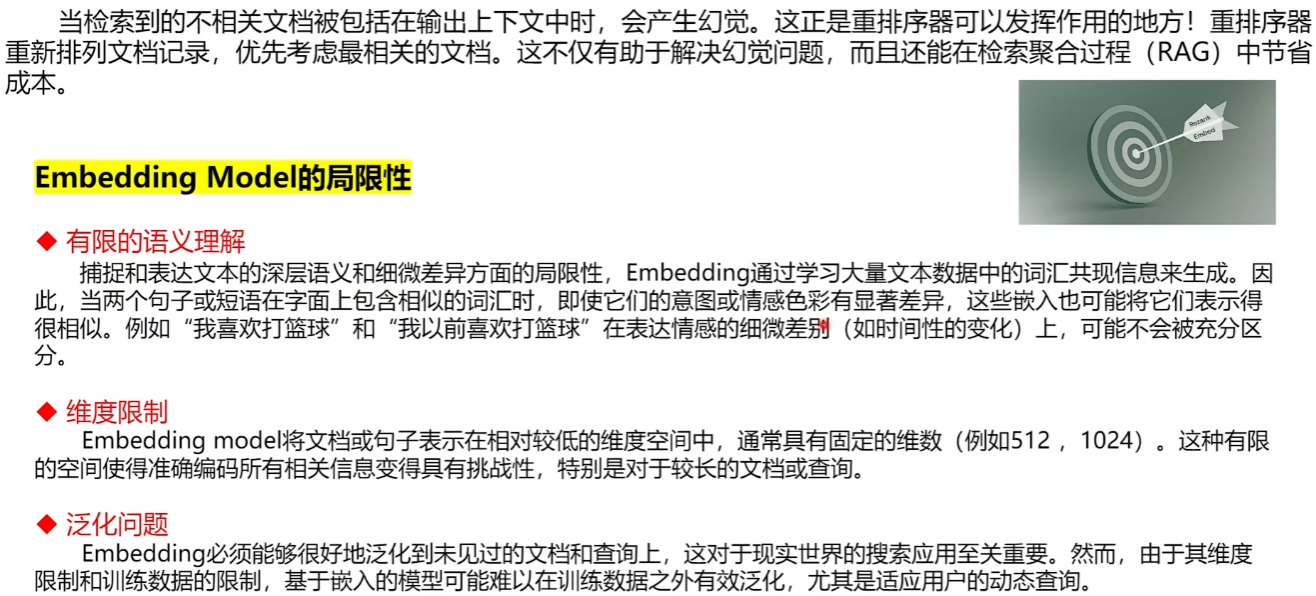

#https://mp.weixin.qq.com/s/rNJa5nb5_J1jHiIZ0WtE_w
+ 1.切片很粗暴
+ 2.检索不精准
+ 3.没有大局观